# Task 8 - Network Activity Anomalies

## Analytical Question

**Which days experienced unusual Ethereum network activity?**

The analysis uses a data-driven method to identify anomalies rather than selecting spikes or drops based on visual inspection alone.

### Metrics investigated

- Daily transaction count
- Daily active addresses
- Daily gas usage
- Daily gas price
- Average transactions per block

### Statistical method

A **z-score** will be used:

z = value - mean / standard deviation

A day will be flagged as unusual when:

**`|z| >= 2`**

The analysis is performed using the analytical datasets already produced by Tasks 1–5.


## 1. Load the Existing Analytical Datasets

No new blockchain extraction is required for this task.

The datasets were already prepared during Tasks 1–5.


In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

daily_transactions = pd.read_csv(
    "../data/processed/daily_transactions.csv"
)

daily_active_addresses = pd.read_csv(
    "../data/processed/daily_active_addresses.csv"
)

daily_network_utilization = pd.read_csv(
    "../data/processed/daily_network_utilization.csv"
)

daily_gas_activity = pd.read_csv(
    "../data/processed/daily_gas_activity.csv"
)

daily_transactions["date"] = pd.to_datetime(daily_transactions["date"])
daily_active_addresses["date"] = pd.to_datetime(daily_active_addresses["date"])
daily_network_utilization["date"] = pd.to_datetime(
    daily_network_utilization["date"]
)
daily_gas_activity["date"] = pd.to_datetime(daily_gas_activity["date"])


## 2. Prepare the Analytical Dataset

We will merge the existing daily datasets using the common `date` field.

The analysis window contains **31 calendar dates**, but the first and last dates are partial days:

- **August 24, 2026:** partial start day
- **September 23, 2026:** partial end day
- **August 25–September 22, 2026:** 29 complete days

Because partial days have fewer observations by definition, they are excluded from the spike analysis to avoid falsely identifying them as unusual.

required fields:

- transaction count
- active addresses
- average transactions per block
- total gas used
- average gas price


In [45]:
df = (
    daily_transactions
    .merge(
        daily_active_addresses,
        on="date",
        how="inner"
    )
    .merge(
        daily_network_utilization[
            [
                "date",
                "avg_transactions_per_block",
                "total_gas_used"
            ]
        ],
        on="date",
        how="inner"
    )
    .merge(
        daily_gas_activity[
            [
                "date",
                "avg_gas_price_gwei"
            ]
        ],
        on="date",
        how="inner"
    )
    .sort_values("date")
    .reset_index(drop=True)
)

df.head()

,date,transaction_count,active_addresses,avg_transactions_per_block,total_gas_used,avg_gas_price_gwei
0,2026-08-24,1157222,421690,276.847368,126843024122,2.659777
1,2026-08-25,1994723,672803,278.048927,218050922535,0.846301
2,2026-08-26,1898276,612723,264.678751,217769296656,0.766541
3,2026-08-27,1931985,645948,269.078691,218437823137,0.916385
4,2026-08-28,1902964,616346,265.332404,218212568813,0.886904


## 3. Validate the Dataset

Check the row count, columns, missing values, duplicate dates, and analysis window.


In [46]:
print("Shape:", df.shape)

print("\nMissing values:")
print(df.isna().sum())

print("\nDuplicate dates:", df["date"].duplicated().sum())

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())


Shape: (31, 6)

Missing values:
date                          0
transaction_count             0
active_addresses              0
avg_transactions_per_block    0
total_gas_used                0
avg_gas_price_gwei            0
dtype: int64

Duplicate dates: 0

Date range:
2026-08-24 00:00:00 to 2026-09-23 00:00:00


##  Partial-Day Handling

The exact analysis window produces 31 calendar dates. The first and last dates are partial days and are excluded from comparable-day statistics.


In [47]:
# The two partial days
first_date = df["date"].min()
last_date = df["date"].max()

# keep only complete days 
complete_days = df[
    (df["date"] > first_date)
    & (df["date"] < last_date)
].copy()

complete_days.shape

(29, 6)

## 4. Calculate Z-Scores

Calculate a z-score for each network activity metric using **only the 29 complete days**.

A positive z-score means the daily value is above the 29-day mean, while a negative z-score means it is below the mean.  
Zero shows that the data point is exactly at the mean.

The z-score formula is:

**z = (x - mean) / standard deviation**


In [48]:
metrics = [
    "transaction_count",
    "active_addresses",
    "avg_transactions_per_block",
    "total_gas_used",
    "avg_gas_price_gwei"
]

for metric in metrics:
    mean = complete_days[metric].mean()
    std = complete_days[metric].std()

    complete_days[f"{metric}_zscore"] = (
        (complete_days[metric] - mean) / std
    )

zscore_columns = [
    f"{metric}_zscore"
    for metric in metrics
]

complete_days[["date"] + zscore_columns].head()

,date,transaction_count_zscore,active_addresses_zscore,avg_transactions_per_block_zscore,total_gas_used_zscore,avg_gas_price_gwei_zscore
1,2026-08-25,0.621498,0.453825,0.614206,0.541294,0.225810
2,2026-08-26,-0.023291,-0.280854,-0.024028,0.005652,-0.344092
3,2026-08-27,0.202068,0.125433,0.186006,1.277164,0.726572
4,2026-08-28,0.008050,-0.236551,0.007175,0.848739,0.515922
5,2026-08-29,0.886354,-0.698391,0.872158,1.353789,-2.499547


## 5. Identify Unusual Days

Flag each metric independently when its absolute z-score is at least 2.

Only the **29 complete days** are included in this analysis.


In [49]:
for metric in metrics:
    complete_days[f"{metric}_spike"] = (
        complete_days[f"{metric}_zscore"].abs() >= 2
    )

spike_columns = [
    f"{metric}_spike"
    for metric in metrics
]

complete_days["metrics_flagged"] = complete_days[spike_columns].sum(axis=1)

spike_days = complete_days[complete_days["metrics_flagged"] > 0].copy()

spike_days[
    ["date", "metrics_flagged"] + zscore_columns
]


,date,metrics_flagged,transaction_count_zscore,active_addresses_zscore,avg_transactions_per_block_zscore,total_gas_used_zscore,avg_gas_price_gwei_zscore
5,2026-08-29,1,0.886354,-0.698391,0.872158,1.353789,-2.499547
6,2026-08-30,1,-0.716602,-1.568487,-0.722592,2.031516,-1.092092
17,2026-09-10,1,1.303083,2.367562,1.300368,-0.043856,-0.670318
19,2026-09-12,2,-2.209698,-1.588810,-2.205129,-0.001922,0.524858
20,2026-09-13,3,-2.844846,-2.217751,-2.845408,0.854324,0.300225
22,2026-09-15,1,-0.048849,-0.211385,-0.045956,-0.658903,2.277336
28,2026-09-21,2,1.226589,0.763655,1.270817,-2.209487,2.380716
29,2026-09-22,1,1.285788,1.167264,1.326054,-2.307488,-0.103496


## 6. Identify Multi-Metric Spikes

A day that is unusual across several metrics provides stronger evidence of a broad network-level anomaly than a movement in a single metric.

We identify days where **at least two metrics** have `|z| >= 2`.

Only the 29 complete days are considered.


In [50]:
multi_metric_spikes = (
    complete_days[complete_days["metrics_flagged"] >= 2]
    [
        ["date", "metrics_flagged"] + metrics
    ]
    .sort_values(
        ["metrics_flagged", "date"],
        ascending=[False, True]
    )
)

multi_metric_spikes


,date,metrics_flagged,transaction_count,active_addresses,avg_transactions_per_block,total_gas_used,avg_gas_price_gwei
20,2026-09-13,3,1476230,454329,205.574433,218215505326,0.856716
19,2026-09-12,2,1571235,505762,218.987456,217765314373,0.888154
28,2026-09-21,2,2085232,698140,291.804086,216604636513,1.147890


## 7. Visualize Transaction Activity

Let's plot the main network activity metrics separately using the **29 complete days**.



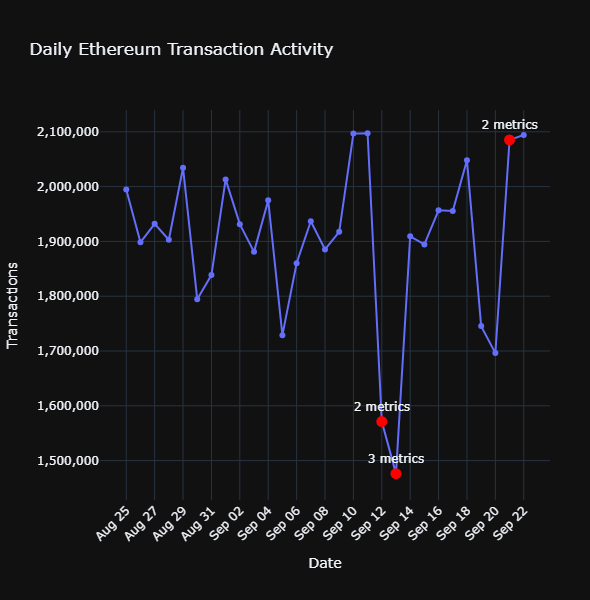

In [51]:
import plotly.express as px


# Create the line chart
fig = px.line(
    complete_days,
    x="date",
    y="transaction_count",
    title="Daily Ethereum Transaction Activity",
    markers=True,
    labels={
        "date": "Date",
        "transaction_count": "Transactions"
    }
)


# Chart layout
fig.update_layout(
    template="plotly_dark",
    hovermode="x unified",
    height=600,

    margin=dict(
        l=70,
        r=40,
        t=110,
        b=100
    ),

    xaxis=dict(
        title="Date",
        hoverformat="%b %d, %Y",
        nticks=20,
        tickformat="%b %d",
        tickangle=-45
    ),

    yaxis=dict(
        title="Transactions",
        tickformat=",",
        fixedrange=True
    )
)


# Format line and hover information
fig.update_traces(
    marker=dict(size=6),
    hovertemplate=(
        "%{y:,} transactions"
        "<extra></extra>"
    )
)


# Mark unusual days
unusual_days = complete_days[
    complete_days["metrics_flagged"] >= 2
]

fig.add_scatter(
    x=unusual_days["date"],
    y=unusual_days["transaction_count"],
    mode="markers+text",
    text=[
        "2 metrics",
        "3 metrics",
        "2 metrics"
    ],
    textposition="top center",
    marker=dict(
        size=11,
        color="red"
    ),
    showlegend=False,
    hovertemplate=(
        "<b>Unusual network activity</b><br>"
        "%{x|%b %d, %Y}<br>"
        "%{y:,} transactions"
        "<extra></extra>"
    )
)


fig.show()

## Visualize Average Gas Price

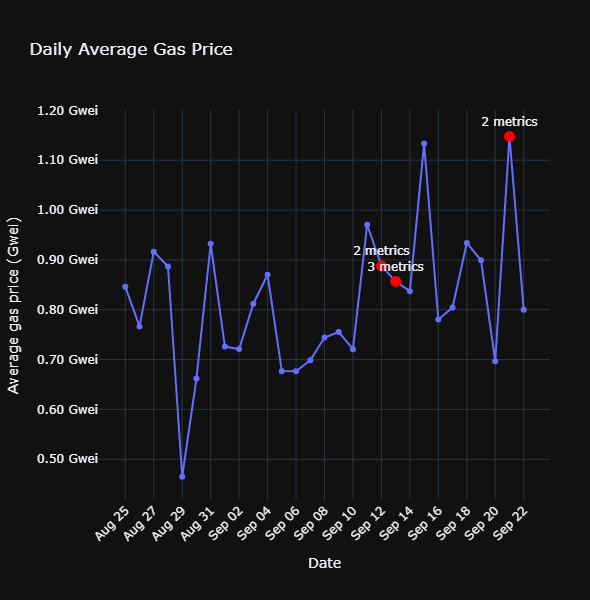

In [52]:
# Create the line chart
fig = px.line(
    complete_days,
    x="date",
    y="avg_gas_price_gwei",
    title="Daily Average Gas Price",
    markers=True,
    labels={
        "date": "Date",
        "avg_gas_price_gwei": "Average gas price (Gwei)"
    }
)


# Chart layout
fig.update_layout(
    template="plotly_dark",
    hovermode="x unified",
    height=600,

    margin=dict(
        l=70,
        r=40,
        t=110,
        b=100
    ),

    xaxis=dict(
        title="Date",
        hoverformat="%b %d, %Y",
        nticks=20,
        tickformat="%b %d",
        tickangle=-45
    ),

    yaxis=dict(
        title="Average gas price (Gwei)",
        tickformat=".2f",
        ticksuffix=" Gwei",
        fixedrange=True
    )
)


fig.update_traces(
    marker=dict(size=6),
    hovertemplate=(
        "%{y:.2f} Gwei"
        "<extra></extra>"
    )
)


# Mark unusual days
fig.add_scatter(
    x=unusual_days["date"],
    y=unusual_days["avg_gas_price_gwei"],
    mode="markers+text",
    text=[
        "2 metrics",
        "3 metrics",
        "2 metrics"
    ],
    textposition="top center",
    marker=dict(
        size=11,
        color="red"
    ),
    showlegend=False,
    hovertemplate=(
        "<b>Unusual network activity</b><br>"
        "%{x|%b %d, %Y}<br>"
        "%{y:.2f} Gwei"
        "<extra></extra>"
    )
)


fig.show()

## Visualize Number of Metrics Flagged

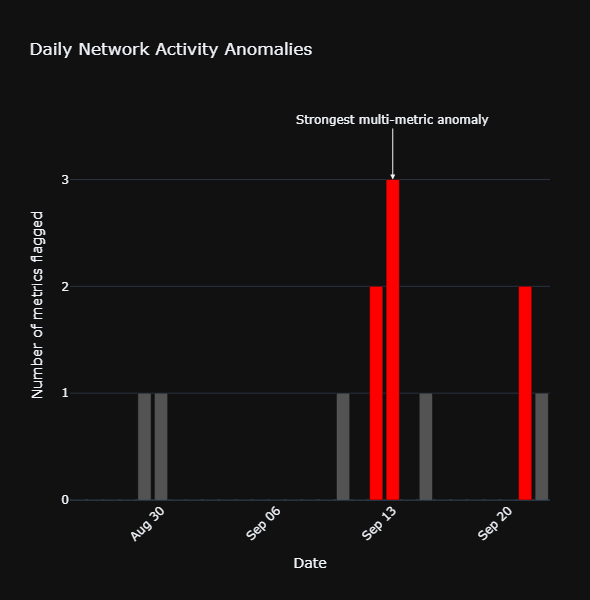

In [53]:
# Create a copy for plotting
plot_df = complete_days[
    ["date", "metrics_flagged"]
].copy()


# Create the bar chart
fig = px.bar(
    plot_df,
    x="date",
    y="metrics_flagged",
    title="Daily Network Activity Anomalies",
    labels={
        "date": "Date",
        "metrics_flagged": "Metrics flagged"
    }
)


# Chart layout
fig.update_layout(
    template="plotly_dark",
    height=600,

    margin=dict(
        l=70,
        r=40,
        t=110,
        b=100
    ),

    xaxis=dict(
        title="Date",
        tickformat="%b %d",
        tickangle=-45
    ),

    yaxis=dict(
        title="Number of metrics flagged",
        dtick=1,
        fixedrange=True
    )
)


# Highlight the multi-metric anomaly days
fig.update_traces(
    marker=dict(
        color=[
            "red" if value >= 2 else "rgba(150,150,150,0.5)"
            for value in plot_df["metrics_flagged"]
        ]
    ),
    hovertemplate=(
        "<b>%{x|%b %d, %Y}</b><br>"
        "Metrics flagged: %{y}"
        "<extra></extra>"
    )
)


# Add annotation to the strongest anomaly
fig.add_annotation(
    x=pd.Timestamp("2026-09-13"),
    y=3,
    text="Strongest multi-metric anomaly",
    showarrow=True,
    arrowhead=2,
    ax=0,
    ay=-60
)


fig.show()

## Finding | Evidence | Meaning

### Finding

The z-score analysis identified **three days with unusually broad network activity**, based on multiple metrics simultaneously exceeding the `|z| >= 2` threshold.

### Evidence

- **Detection method:** A z-score threshold of **`|z| >= 2`** was used to identify unusual observations.
- **Analysis period:** **August 25 to September 22, 2026**, covering 29 complete days.
- **Partial days excluded:** August 24 and September 23 were excluded because they represent the partial start and end days of the 30-day analysis window.
- **Metrics analyzed:** transaction count, active addresses, average transactions per block, total gas used, and average gas price.
- **September 12:** **2 metrics** were simultaneously flagged as unusual.
- **September 13:** **3 metrics** were simultaneously flagged as unusual.
- **September 21:** **2 metrics** were simultaneously flagged as unusual.
- **September 13** had the highest number of simultaneously unusual metrics, with **3 of the 5 metrics** flagged.

### Meaning

The multi-metric results indicate that **September 12, September 13, and September 21 experienced broader-than-usual deviations across network activity measures** relative to the 29 complete-day baseline. September 13 showed the broadest deviation because three metrics were simultaneously unusual.

The z-score method identifies observations that were unusual relative to the analysis period; it does **not establish the cause** of the observed deviations.

Do not infer the cause of a spike from these metrics alone.

## Limitations

- The analysis covers only a **30-day period**, so the unusual activity identified here may not represent longer-term Ethereum network behavior.

- The anomaly detection method identifies observations that are statistically unusual relative to the other days in the analysis period. It does **not determine why** the activity was unusual.

- A day being flagged as unusual does not necessarily mean that network activity increased. The method can identify unusually high **or low** observations depending on the direction of the z-score.

- The analysis considers multiple network metrics, including **transaction count, active addresses, gas usage, gas price, and transactions per block**. These metrics capture different aspects of network activity, so an anomaly in one metric does not necessarily imply an anomaly in the others.

- The identified unusual days should therefore be treated as **signals for further investigation rather than evidence of a specific event or cause**.

- The analysis identifies statistical patterns in the available blockchain data but does not establish **causation or the external events responsible for the observed activity**.